### Import Libraries : Exhaustive list, not all being used

In [1]:
from PIL import Image

import os
dir_path = 'C:/Admin/CQF Course/Python Labs/'

In [1]:
# data manipuation
import pandas as pd
import numpy as np

# panda technical analysis 
import pandas_ta as ta

# data visualization
import matplotlib as mpl

import matplotlib.pyplot as plt
plt.rcParams['figure.figsize'] = (10,6)
plt.style.use ='seaborn'
plt.rcParams['font.size'] = 8

#-------------------------------------------------------------------------------------------------------------
# statistical visual representation
import seaborn as sns

import cufflinks as cf                                                        # new package - cufflinks
cf.set_config_file(offline=True, theme='pearl',dimensions=((1000,600)))       # cf.set_config() -- (w,h)

import plotly.express as px
px.defaults.width, px.defaults.height = 1000,600

#-------------------------------------------------------------------------------------------------------------
# Self organizing maps(SOM)
from minisom import MiniSom

#-------------------------------------------------------------------------------------------------------------
# K-means clustering(KMC)
from sklearn.cluster import KMeans

# scikit learn(sklearn) package is used primarily for machine learning
# always remember to perform pre-processing and model selcetion before using model implementation
import sklearn
from sklearn.preprocessing import MinMaxScaler,StandardScaler
from sklearn.model_selection import train_test_split,TimeSeriesSplit,cross_val_score,GridSearchCV,RandomizedSearchCV

from sklearn.pipeline import Pipeline

# sklearn evaluation metrics
from sklearn.metrics import precision_recall_curve, roc_curve,RocCurveDisplay,ConfusionMatrixDisplay
from sklearn.metrics import accuracy_score, f1_score, recall_score,precision_score,roc_auc_score,auc
from sklearn.metrics import classification_report, confusion_matrix

# Regression
from sklearn.linear_model import LinearRegression, Lasso, Ridge, ElasticNet

# K-means clustering(KMC)
from sklearn.cluster import KMeans

# Support Vector Machine(SVM)
from sklearn.svm import SVC

# DTEM(Decision Trees and Ensemble Models) - Bagging - Random Forest
from sklearn.ensemble import RandomForestClassifier

# K nearest neighbours(KNN)
from sklearn.neighbors import KNeighborsClassifier

# Principal Component Analysis(PCA)
from sklearn.decomposition import PCA

#-------------------------------------------------------------------------------------------------------------
# DTEM(Decision Trees and Ensemble Models) - Boosting - Gradient Boosting(Extreme Gradient Boosting)
from xgboost import XGBClassifier,plot_importance,to_graphviz

#-------------------------------------------------------------------------------------------------------------
# statistical analysis & optimization
import scipy.stats as scs
import scipy.optimize as sco
from scipy.interpolate import interp1d
from scipy.integrate import simpson
from scipy.interpolate import CubicSpline

# statsmodels is a Python package that provides a complement to scipy for statistical computations
import statsmodels.api as sm
from statsmodels.tsa.api import VAR
from statsmodels.tsa.statespace.varmax import VARMAX
from statsmodels.tsa.seasonal import seasonal_decompose
from statsmodels.tsa.ar_model import AutoReg
from statsmodels.tsa.arima.model import ARIMA
from statsmodels.tsa.stattools import adfuller, coint, grangercausalitytests
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf

#-------------------------------------------------------------------------------------------------------------
# Nelson Siegel Svensson Model
from nelson_siegel_svensson import NelsonSiegelCurve, NelsonSiegelSvenssonCurve
from nelson_siegel_svensson.calibrate import calibrate_ns_ols, calibrate_nss_ols

#-------------------------------------------------------------------------------------------------------------
# SABR(Stochastic Alpha, Beta, Rho)
from pysabr import Hagan2002LognormalSABR
from pysabr import Hagan2002NormalSABR
from pysabr.helpers import year_frac_from_maturity_label

#-------------------------------------------------------------------------------------------------------------
# Shapley values, used in DTEM
import shap

#-------------------------------------------------------------------------------------------------------------
# Quantlib package
from QuantLib import *

#-------------------------------------------------------------------------------------------------------------
# Pyfolio package used for strategy backtesting
import pyfolio as pf

# to reload another python script 
from importlib import reload

# Ignore warnings - optional
import warnings
warnings.filterwarnings('ignore')

# data retrival
import yfinance as yf
 
# float display
pd.options.display.float_format = '{:0.4f}'.format

# operating system
import os

# Image package
from PIL import Image

# table formation
from tabulate import tabulate

# datetime handling
from datetime import datetime

import itertools

ModuleNotFoundError: No module named 'pandas_ta'

### Implied Volatility

- In Option pricing, implied volatility is the value of volatility of underlying instrument that, when plugged into any given option pricing formula, reproduces the actual price of the option

- Implied volatility is the one aspect of the option pricing that can not be observed.

### Volatility Smile

- A volatility smile refers to a U shaped graphical represtation of pattern created by implied volatilities os multiple option contracts that share the same date of expiration

- the data recorded in a situation where out-of-the-money or in-the-money options show higher implied volatility than that of the at-the-money option is known as smile


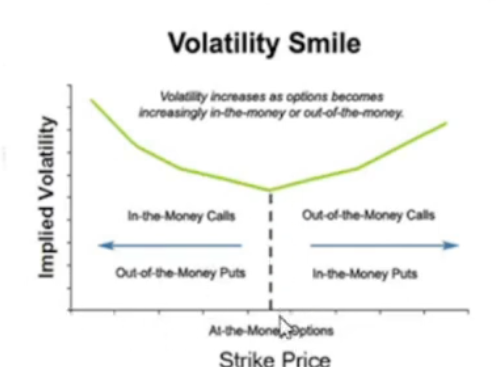

In [15]:
Image.open(os.path.join(dir_path, "Self SABR Model/pic_1.PNG"))

### Theoretical framework about SABR

- SABR Model is stochastic volatility model, which attempts to capture volatility smile in derivative markets. this stands for **stochastic alpha, beta and rho** model i.e. parameters of the model. this is primarily used in interest rate derivative market.

- The SABR model is used to model a forward Libor rate, a forward swap rate , a forward index price or any other forward rate.this is an extension to Black's model and CEV(Constant Elasticity of Variance)

- The Model is not pure option pricing model but a stochastic volatility model.But unlike other stochastic volatility models such as Heston model, this doesn't produce option prices directly. Rather, **it produces an estimation of the implied volatility curve, which is subsequently used as an input in Black's model to price Swaption, Caps and other intererst rate drivates.**

### SABR Model Formula

Instantaneous forward interest rate with maturity T is assumed to satisfy stochastic differential equation

$df_t = \alpha_t(f_t)^\beta dW_1$

$d\alpha_t = \nu(\alpha_t) dW_2$

$dW_1dW_2 = \rho dt$

with initial values $f = f_0$ and $\alpha = \alpha_0$
$f_t$ is the forward rate and $\alpha_t $ is the volatility

$W_1(t)$ and $W_2(t)$ are correlated browian motions with correlation $\rho$

$\nu, \beta, and \rho $ determine SABR $\alpha$ which is computed internally 

**in practice, setting $\beta$ =0.5 is quite adequate for most purposes.**

A SABR model extension for negative interest rates that has gained popularity in recent years is the shifted SABR model, where the shifted forward rate is assumed to follow a SABR process

$df_t = \alpha_t(f_t + s)^\beta dW_1(t)$

$d\alpha_t = \nu(\sigma_t) dW_2(t)$

$dW_1(t)dW_2(t) = \rho dt$

where s is shift parameter

### Parameters definition -  $\alpha$, $\beta$, $\rho$ and $\nu$,

**Beta - $\beta$**

- Exponent of forward rate **because in equation it comes as an exponent**, (also called CEV parameter)constant for each forward rate under consideration that determine the underlying distribution of the forward process.
- case $\beta$ = 0, produces stochastic normal model
- case $\beta$ = 1, produces stochastic lognormal model
- case $\beta$ = 1/2, produces stochastic CIR model


**Rho - $\rho$**

- correlation between forward and diffusion process.
- Rho affect the slope of modelled volatility curve.
- It Controls the volatility skew

**Nu $\nu$**

- the volatility of volatility, constant for each forward rate process
- it affect the height of volatility smile
- it control volatility curvature

### Complete process chart

Shifted SABR Calibration Workflow using `pysabr`

This notebook explains:

- Market data used as input
- Parameters calibrated
- Role of the shift parameter
- Construction of the implied volatility surface
- Usage of `pysabr` Hagan functions (`normal_vol` and `lognormal_vol`)



#### Step 1. Market Data Used as Input----------------------------------------------

For each **Expiry × Swap Tenor** combination, the following market data are required.

1. **Forward Rate**
- Forward swap rate (for swaptions)
- Forward FRA rate (for cap/floor)

Denote it by F

2. **Market Implied Volatilities**
Quoted for several strikes.
Depending on the market convention, these are either
- Normal (Bachelier) implied volatilities
- Lognormal (Black) implied volatilities

Example:

| Strike | Normal Vol |
|---------|------------|
| -1.0% | 62 bp |
| -0.5% | 55 bp |
| ATM | 48 bp |
| +0.5% | 52 bp |
| +1.0% | 60 bp |

or

| Strike | Black Vol |
|---------|-----------|
| 1.0% | 38% |
| 2.0% | 32% |
| ATM | 29% |
| 4.0% | 31% |


3. **Strike Grid**
$K_1,K_2,\ldots,K_n$

4. **Expiry**
$T$

5. **Shift** (Shifted SABR)
If shifted SABR is used,
$F_s=F+s$,
$K_s=K+s$
where \(s\) = shift parameter.
The shift is **fixed** and is **not calibrated**.


#### Step 2. SABR Parameters---------------------------------------------------

The SABR model has four parameters
$(\alpha,\beta,\rho,\nu)$
where
- $\alpha$ : Initial volatility
- $\beta$ : Elasticity parameter
- $\rho$ : Correlation
- $\nu$ : Volatility of volatility



In Industry Practice Usually $\beta$ is fixed.

Typical choices are

| β | Interpretation |
|---|----------------|
| 0 | Normal SABR |
| 0.5 | Interest Rate SABR |
| 1 | Lognormal SABR |

#### Step 3. Which Parameters are Calibrated?---------------------------------

The most common market practice is
- Fix β
- Fix Shift
Derive $\alpha$ from the ATM volatility.

Only $\rho$ and $\nu$ are optimized.

**ATM Condition**

For every optimization step,

$\sigma_{\text{model}}(K=F;\alpha,\beta,\rho,\nu)=\sigma_{\text{ATM}}^{\text{market}}$

This equation is solved numerically for $\alpha.$

#### Step 4. Calibration Objective------------------------------------------------

For each strike, Market volatility $\sigma_{\text{market}}(K_i)$ is compared with Model volatility $\sigma_{\text{model}}(K_i;\alpha,\beta,\rho,\nu)$

The optimizer minimizes
$\sum_i\left(\sigma_{\text{market}}(K_i)-\sigma_{\text{model}}(K_i)\right)^2$


#### Step 5. Role of `pysabr`-------------------------------------------------------

During calibration, the optimizer repeatedly calls either **Lognormal SABR** ```pythonhagan.lognormal_vol(...)``` which returns $\sigma_{Black}(K)$ OR  **Normal SABR** ```pythonhagan.normal_vol(...)``` which returns $\sigma_{Normal}(K)$

#### Step 6. Calibration Output-------------------------------------------------------

Suppose calibration returns

| Parameter | Value |
|------------|--------|
| α | 0.012 |
| β | 0.50 |
| ρ | -0.32 |
| ν | 0.45 |

These parameters define the complete smile for that expiry.


#### Step 7. Smile Construction--------------------------------------------------------

Using ```pythonhagan.normal_vol(...)```
OR
```pythonhagan.lognormal_vol(...)```

we compute implied volatility for a dense strike grid

```text
1.00%, 1.10%, 1.20%...2.80%,2.90%,3.00%
```
This generates the volatility smile.

#### Step 8. Volatility Surface Construction------------------------------------------------

Calibration is performed **independently** for every

- Expiry
- Swap Tenor

For example

| Expiry | Swap Tenor | α | ρ | ν |
|---------|------------|---|----|----|
| 1Y | 5Y | ... | ... | ... |
| 2Y | 5Y | ... | ... | ... |
| 5Y | 5Y | ... | ... | ... |
| 10Y | 5Y | ... | ... | ... |

For every (Expiry, Tenor)

- Generate smile across strikes.
- Stack all smiles together.

The result is the implied volatility cube

$\sigma(\text{Expiry},\text{Tenor},K)$


#### Step 9. Normal vs Lognormal Surface-------------------------------------------------------

Using ```pythonhagan.normal_vol(...)``` produces $\sigma_N(\text{Expiry},\text{Tenor},K)$ which is used in the **Bachelier** pricing formula.

Using ```pythonhagan.lognormal_vol(...)``` produces $\sigma_{Black}(\text{Expiry},\text{Tenor},K)$ which is used in the **Black-76** pricing formula.



- Market quotes (F, T, K_i, Market Vol_i, Shift)
- Choose β (usually fixed)
- Initial guess (α, ρ, ν) 
- Call hagan.normal_vol() OR hagan.lognormal_vol()
- Model implied vols
- Compare with market vols
- Optimizer updates (α, ρ, ν)
- Best-fit parameters (α, β, ρ, ν)
- Generate dense strike smile
- Repeat for every expiry
- Final implied volatility surface

### Do we calibrate alpha or it ia derived from ATM vol

- For interest-rate shifted SABR using Hagan's approximation, the first approach (derive α from the ATM volatility) is generally the preferred and more widely used calibration strategy.
- The pysabr package supports the common market approach where α is derived from the ATM volatility, and the calibration focuses on the remaining parameters (typically ρ and ν, with β fixed). This ensures an exact fit at the ATM while fitting the smile through the other parameters.


In many implementations (including common uses of Hagan's approximation and `pysabr`), $\alpha$ is **not** treated as an independent optimization parameter.

Instead:

1. **Fix** $\beta$, $\rho$, $\nu$

2. Use the **market ATM implied volatility** to solve for $\alpha$ such that

$$ \sigma_{\text{model}}(K = F;\alpha,\beta,\rho,\nu) = \sigma_{\text{ATM}}^{\text{market}}$$

Since the ATM Hagan formula is monotonic in $\alpha$, $\alpha$ can be found numerically (or approximately analytically).

Then the optimizer only calibrates: $\rho$, $\nu$

while $\alpha$ is recomputed from the ATM volatility at every optimization step.

### Shift Parameter

The **shift** is used **inside the SABR/Hagan volatility calculation** to handle negative or near-zero forwards.
it is set to ensure that all shifted forwards and strikes remain positive across the entire strikes range of interest. common convention 1% (used when rates are mildly negative), 2%(more common in EUR market post-2015), 3%(used when rates are deeply negative or as a conservative buffer)
The shifted forward and strike are defined as

$
F_{\text{shift}} = F + s,
\qquad
K_{\text{shift}} = K + s
$

where

- $F$ = Forward rate
- $K$ = Strike
- $s$ = Shift parameter


After the Implied Volatility is Computed

**Case 1: Normal Volatility**

If the Hagan function returns a **normal implied volatility**, use it directly in the **Bachelier pricing formula**.

 **Important:** Use the **original** forward rate $F$ and strike $K$ in the Bachelier pricing formula.

>The shift is used **only** to compute the implied volatility.

**Case 2: Black (Lognormal) Volatility**

If the Hagan function returns a **Black (lognormal) implied volatility**, use it in the **Black-76 pricing formula**.

**Important:** Again, use the **original** forward rate $F$ and strike $K$ in the Black-76 pricing formula.

 The shift was used **only** inside the SABR/Hagan approximation to compute the implied volatility.

**Industry Practice (Interest Rate Swaptions)**

**Negative Interest Rate Markets (Historical)**

For EUR and other markets that historically experienced negative interest rates:

- Shifted SABR is calibrated to **Normal (Bachelier) implied volatilities**.
- The resulting **Normal volatility surface** is used in the **Bachelier pricing model**.

**Markets Quoting Black Implied Volatilities**

For markets where implied volatilities are quoted in Black (lognormal) terms:

- Shifted SABR is calibrated to **Black implied volatilities**.
- The resulting **Black volatility surface** is used in the **Black-76 pricing model**.

**Summary**

The type of volatility surface obtained depends on the Hagan function used during calibration.

| Hagan Function | Volatility Surface Produced | Pricing Model |
|---------------|-----------------------------|---------------|
| `hagan.normal_vol()` | Normal Volatility Surface | Bachelier |
| `hagan.lognormal_vol()` | Black (Lognormal) Volatility Surface | Black-76 |

### Implied volatility surface

After SABR calibration, you obtain an implied volatility surface that is typically represented as $\sigma(K,T)$
However, this notation is shorthand.More precisely, the SABR-implied volatility is $\sigma(F,K,T)$

because Hagan's formula depends on:
- Forward $F$
- Strike $K$
- Expiry $T$
- SABR parameters $(\alpha,\beta,\rho,\nu)$

**Why Do We Often Write $\sigma(K,T)$?**

For a given valuation date, each expiry $T$ has a known forward rate $F(T)$, which is derived from the current yield curve (or futures curve) Therefore, the forward is **not an independent variable**. It is fixed once the expiry is specified.
Hence,$F = F(T)$ and therefore $\sigma(F(T),K,T)=\sigma(K,T).$

This is why traders and pricing systems usually refer to the implied volatility surface as a function of **strike** and **expiry** only.


**Summary**

Mathematically,$\sigma=\sigma(F,K,T).$ Since the forward is uniquely determined by the expiry,$F=F(T),$ the implied volatility surface is commonly written as
$\boxed{\sigma(K,T)}$ which is the standard market notation.

### Case 1 Python code - Shifted Lognormal SABR (Black Vol)

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

from pysabr import Hagan2002LognormalSABR
from pysabr import black

# Forward swap rate
f = 0.025

# Shift
shift = 0.03

# Expiry
t = 5.0

# Fixed beta
beta = 0.5

# Step 3. Market data
# Market strikes
k = np.array([0.015,0.020,0.0225,0.025,0.0275,0.030,0.035])
# Market Black vols (% expressed as decimals)
market_vol = np.array([0.145,0.132,0.125,0.120,0.122,0.128,0.140])

# Step 4. Create SABR object
sabr = Hagan2002LognormalSABR(f=f,shift=shift,t=t,beta=beta)

# Step 5. Calibrate
# sabr.fit() is intended for lognormal (Black) SABR
# Here, fit() assumes the market quotes are Black implied volatilities and internally calibrates the lognormal SABR model.There is no equivalent for normal vol
alpha, rho, volvol = sabr.fit(k, market_vol)

# Step 6. Generate smile
k_grid = np.linspace(0.01,0.04,100)
vol = np.array([sabr.lognormal_vol(x)for x in k_grid])

# plot
plt.scatter(k,market_vol,color="red")
plt.plot(k_grid,vol)
plt.xlabel("Strike")
plt.ylabel("Black Vol")
plt.show()

price = black.lognormal_call(k=0.025,f=f,t=t,v=sabr.lognormal_vol(0.025),r=0.02,cp="call")

### Case 2 - Normal SABR (Bachelier Vol)

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

from scipy.optimize import minimize
from scipy.optimize import brentq
from scipy.stats import norm

from pysabr import hagan

# market data
F = 0.025              # Forward Swap Rate
T = 5.0                # Expiry

beta = 0.0             # Normal SABR

shift = 0.02           # Shift (if required)

discount = 0.92
strikes = np.array([0.005,0.010,0.015,0.020,0.025,0.030,0.035,])
market_normal_vol = np.array([0.0105,0.0098,0.0092,0.0089,0.0088,0.0090,0.0095,])
atm_vol = market_normal_vol[4]


# Solve alpha from ATM
def solve_alpha(alpha, rho, nu):
    model_atm = hagan.normal_vol(F,F,T,alpha,beta,rho,nu)

    return model_atm - atm_vol


# Calibration Objective

def objective(params):

    rho, nu = params
    alpha = brentq(solve_alpha,1e-6,5.0,args=(rho, nu))
    model = np.array([hagan.normal_vol(F,K,T,alpha,beta,rho,nu)for K in strikes])

    return np.sum((market_normal_vol-model)**2)


# Calibration SABR
result = minimize(objective,x0=[-0.20,0.50],bounds=[(-0.999,0.999),(0.01,5.0)])
rho,nu = result.x
alpha = brentq(solve_alpha,1e-6,5.0,args=(rho,nu))


# Build Normal Volatility Surface
surface_strikes = np.linspace(0.00,0.05,100)
surface_vol = np.array([hagan.normal_vol(F,K,T,alpha,beta,rho,nu) for K in surface_strikes])


# Plot smile
plt.figure(figsize=(8,5))

plt.plot(surface_strikes,surface_vol,label="SABR")

plt.scatter(strikes,market_normal_vol,color="red",label="Market")

plt.xlabel("Strike")
plt.ylabel("Normal Vol")
grid(True)
plt.legend()
plt.show()


# Bachelier Pricing
def bachelier_call(F,K,sigma,T,discount=1.0):

    std = sigma*np.sqrt(T)
    if std < 1e-12:
        return discount*max(F-K,0)
    d = (F-K)/std
    


# Price One Option
K = 0.03
sigma = hagan.normal_vol(F,K,T,alpha,beta,rho,nu)
price = bachelier_call(F,K,sigma,T,discount)


### Closed form solution

**there is no closed form solution to above equations except Beta = 0 or 1, however below approximationwork well.
This shows how to get Black vols from SABR vol (alpha).**

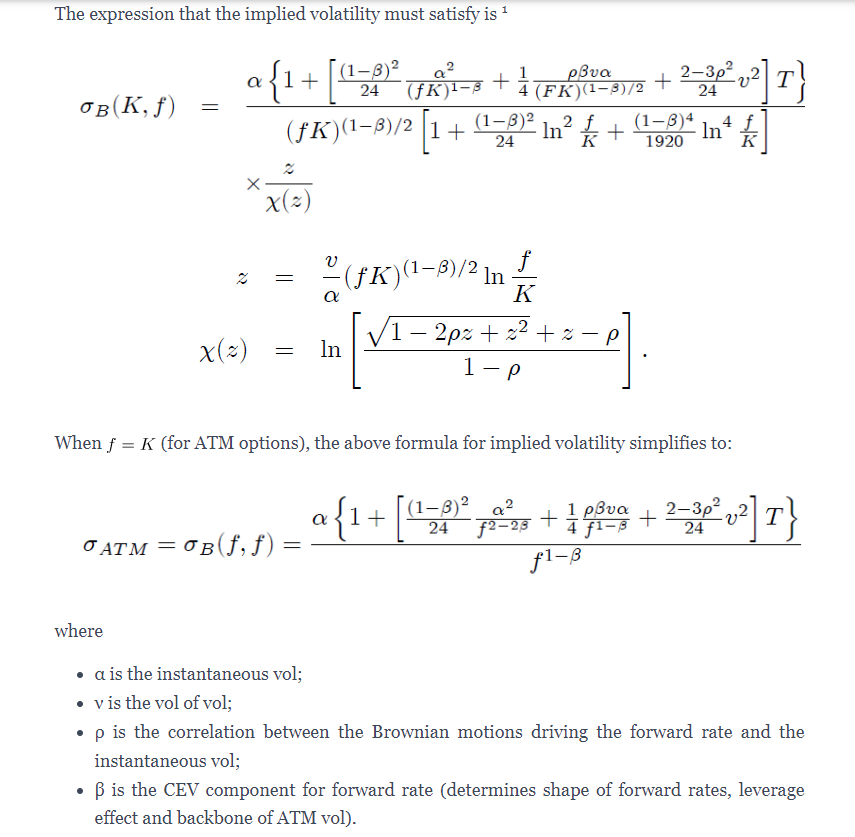

In [14]:
Image.open(os.path.join(dir_path, "Self SABR Model/pic_2.PNG"))

### Calibration of SABR Model Parameters - Alpha, Rho, VolVol

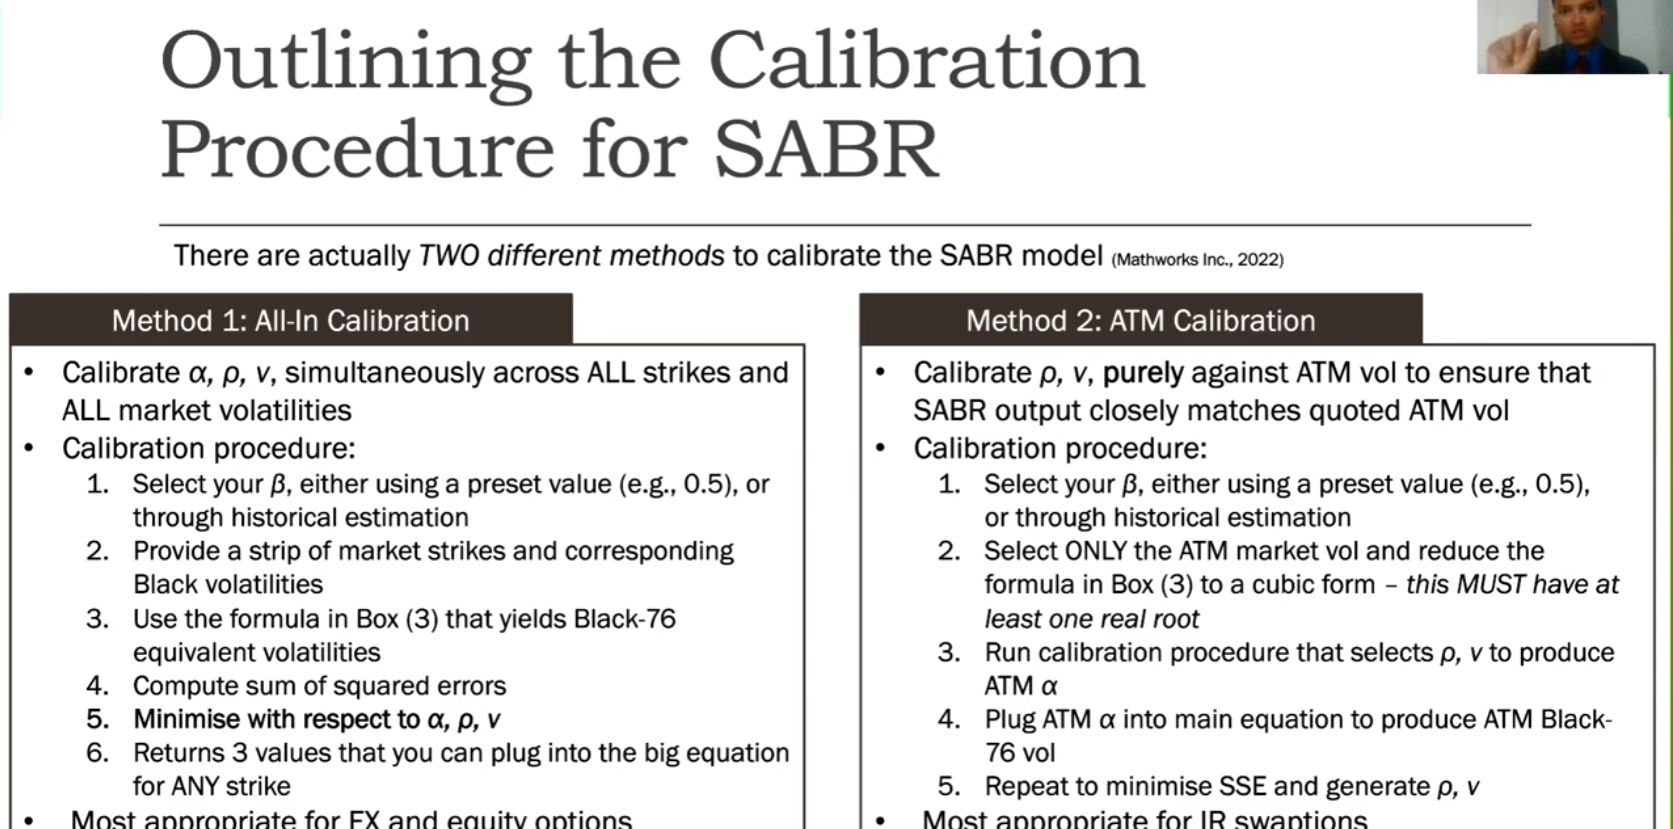

In [16]:
Image.open(os.path.join(dir_path, "Self SABR Model/pic_3.PNG"))

https://bsic.it/sabr-stochastic-volatility-model-volatility-smile/

https://in.mathworks.com/help/fininst/calibrating-the-sabr-model.html

https://quant.stackexchange.com/questions/68141/fitting-a-volatility-smile-with-pysabr-python-implementation-of-sabr-model